## Setup

Clones source repo locally

In [30]:
import shutil
import sys

REPO_URL = "https://github.com/damorim77/zurich-ds-fraud-assignment.git"
REPO_DIR = "zurich-ds-fraud-assignment"


%cd /content

shutil.rmtree(REPO_DIR,ignore_errors=True)

!git clone {REPO_URL}

%cd {REPO_DIR}

!pip install -r requirements.txt --quiet

%cd notebooks
print(sys.version)

/content
Cloning into 'zurich-ds-fraud-assignment'...
remote: Enumerating objects: 108, done.
remote: Counting objects: 100% (108/108), done.
remote: Compressing objects: 100% (90/90), done.
remote: Total 108 (delta 44), reused 43 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (108/108), 26.40 MiB | 35.76 MiB/s, done.
Resolving deltas: 100% (44/44), done.
/content/zurich-ds-fraud-assignment
/content/zurich-ds-fraud-assignment/notebooks
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


Adds custom python scripts to the path

In [31]:
import sys
from glob import glob
import pandas as pd

# Make pandas show all columns from the dataset
pd.set_option('display.max_columns', None)
# Adds `scripts` folder to path
sys.path.insert(0,glob("../scripts")[0] )

## Show me the data

Queries source previously converted data file using duckdb for faster reading

In [32]:
import duckdb

parquet_path = '../data/landing/data.parquet'

query = f"SELECT * FROM '{parquet_path}' ORDER BY RANDOM()"
df = duckdb.query(query).to_df()

display(df.head(10))

,amountInsured,backupCar,claimCoverage,claimDriver,claimDriverId,claimEventId,claimGroup,claimId,claimStatus,claimValue,classOfClaim,dateFNOL,dateOcurr,datePolEnd,datePolStart,internalClaimFlag,driverDtOfBirth_claim,eventCause,eventSubCause,eventType,hourOfEvent,insuredEmail,insuredId_claim,judicialFlag,licensePlate,notifier,notifierId,personalInjury,policeRepOnline,policeReport,policyId_claim,typeOfClaim,under25Cov,vinNumber_claim,extRepairFlag,repairId,fraudStatus,deductiAmount,deductibleType,ftAdjust,grossWrtPrem,insuDateOfBirth,mainDriverId,newCar,policyStatus,prevPolicyId,vehManuYear,brand,useOfVehicle,vehModelYear,vehicleCategory,birthdate,mobileNumber,telephone,gender
0,4431616.05,No,Collision,Owner,1093562,1102431.0,Partial loss,1103933,Closed,118809.94,64,2022-06-02 08:54:18,2022-06-01,2023-03-12,2022-03-13,No,1988.0,Collision with a car,Driver - other action,Collision,1970-01-01 16:00:00,1181055,1125884,No,1226358,Insured's broker,1104416,No,No,No,1342859,Third party,No,1197417,None,NaN,None,2613705.11,A - Reduced (50%),100.0,199245.46,NaN,1111893,No,Active,1007411,2019-01-01,B0059,None,NaT,Car,2003.0,1106736.0,1198464.0,F
1,0.00,No (v2),Collision (v3),Insured,1230296,1196614.0,Total loss,1201607,Closed,763125.99,71,NaT,2020-08-21,NaT,NaT,No,1985.0,Collision with a car,Driver - other action,Collision,NaT,1355449,1230296,No,1275021,Insured,1230296,No (v2),No (v2),No (v2),1341401,Own vehicle,None,1006096,None,NaN,Not confirmed,5319788.21,A - Reduced (50%),100.0,43713.99,1985.0,1230296,No,Active,1340592,2018-01-01,B0037,"Leisure / commuting only, no commercial purpose",2018-01-01,"Passenger car, imported (non-sport)",1985.0,1113350.0,1320307.0,M
2,441142.02,No,Collision,Main policy driver,1003261,1129766.0,Partial loss,1055129,Closed,41303.26,71,2022-12-19 09:27:43,2022-12-18,2023-03-17,2022-03-18,No,1973.0,"Multiple collision (objects, people, vehicles)",Driver - other action,Collision,1970-01-01 08:30:00,1125531,1003261,No,1218169,Insured,1003261,No,No,No,1175973,Own vehicle,No,1289890,None,NaN,None,1763377.77,A - Reduced (50%),100.0,2019441.65,1973.0,1003261,No,Active,1137003,2018-01-01,B0121,"Leisure / commuting only, no commercial purpos...",2018-01-01,Car,1973.0,1264236.0,1118447.0,M
3,460785.63,No,Collision (v2),Other,1201990,1300851.0,Partial loss,1354808,Closed,14655.66,64,NaT,2019-09-04,2019-10-19,2018-10-19,No,1995.0,Collision with a car,Turning left or right,Collision,1970-01-01 17:30:00,1116006,1041272,No,1113498,None,1201990,No,No,No,1120539,Third party,No,1035396,None,NaN,None,16546.81,A - Reduced (50%),100.0,18028.51,1995.0,1041272,No,Active,1340592,2009-01-01,B0065,"Leisure / commuting only, no commercial purpos...",2009-01-01,Passenger car (non-sport),1995.0,1161334.0,1141538.0,F
4,265963.40,No,Collision,Insured,1008454,1034049.0,Total loss,1066009,Closed,273972.90,71,2021-02-02 10:21:08,2021-02-02,2021-12-01,2020-12-02,No,1979.0,Collision with a car,Driver - other action,Collision,1970-01-01 10:00:00,1182748,1008454,No,1044029,Insured,1008454,No,No,No,1223609,Own vehicle,No,1280361,None,NaN,None,1810927.85,A - Reduced (50%),100.0,2216870.12,NaN,1008454,No,Active,1340592,2013-01-01,B0098,"Leisure / commuting only, no commercial purpos...",2013-01-01,Car,1979.0,1162858.0,1285189.0,M
5,856339.09,No,Collision,Other,1209832,1198889.0,Total loss,1128213,Closed,108467.93,64,2021-11-17 20:04:43,2021-11-14,2022-02-10,2021-02-11,No,1994.0,Collision with a car,Driver - crossed at a pedestrian crossing,Collision,1970-01-01 12:30:00,1233564,1025066,No,1168777,None,1209832,No,No,No,1210099,Third party,Yes,1285141,None,NaN,Not confirmed,0.00,nan,100.0,1474341.89,1984.0,1025066,No,Active,1340592,2016-01-01,B0144,None,NaT,Car,1984.0,1342205.0,1112430.0,M
6,329623.43,No,Collision (v2),Main policy driver,1121636,1367753.0,Partial loss,1047008,Closed,95467.75,71,2020-03-12 00:00:00,2020-03-12,2020-09-03,2019-09-03,No,1970.0,Collision with a car,Driver - other action,Collision,1970-01-01 12:00:00,1130263,1010025,No,126213

In [33]:
df.shape

(63944, 55)

## Quick-and-dirty EDA

Runs automated EDA on the dataset to obtain descriptive statistics

In [ ]:
# Sweetviz is a handy package for automated EDA
import sweetviz as sv
import numpy as np

# Create a temp dataframe
df_temp = df.copy()

# Identifier-like columns: numeric codes that should be treated as strings.
custom_cols = ['telephone', 'mobileNumber', 'insuredEmail', 'licensePlate', 'vinNumber_claim']
id_cols = [c for c in df_temp.columns if "Id" in c or c in custom_cols]

# Vectorized string conversion avoiding loops and protecting null values
df_temp[id_cols] = df_temp[id_cols].astype(str).where(df_temp[id_cols].notna(), np.nan)

# Run the Sweetviz analysis
# sv.analyze(df_temp).show_notebook(w=1000, h=800)
del df_temp

## Peculiarities deep-dive

### Identification of placeholder values

Performing a frequency analysis to detect whether there repeatable values that may be potencial placeholder values on all id-like columns

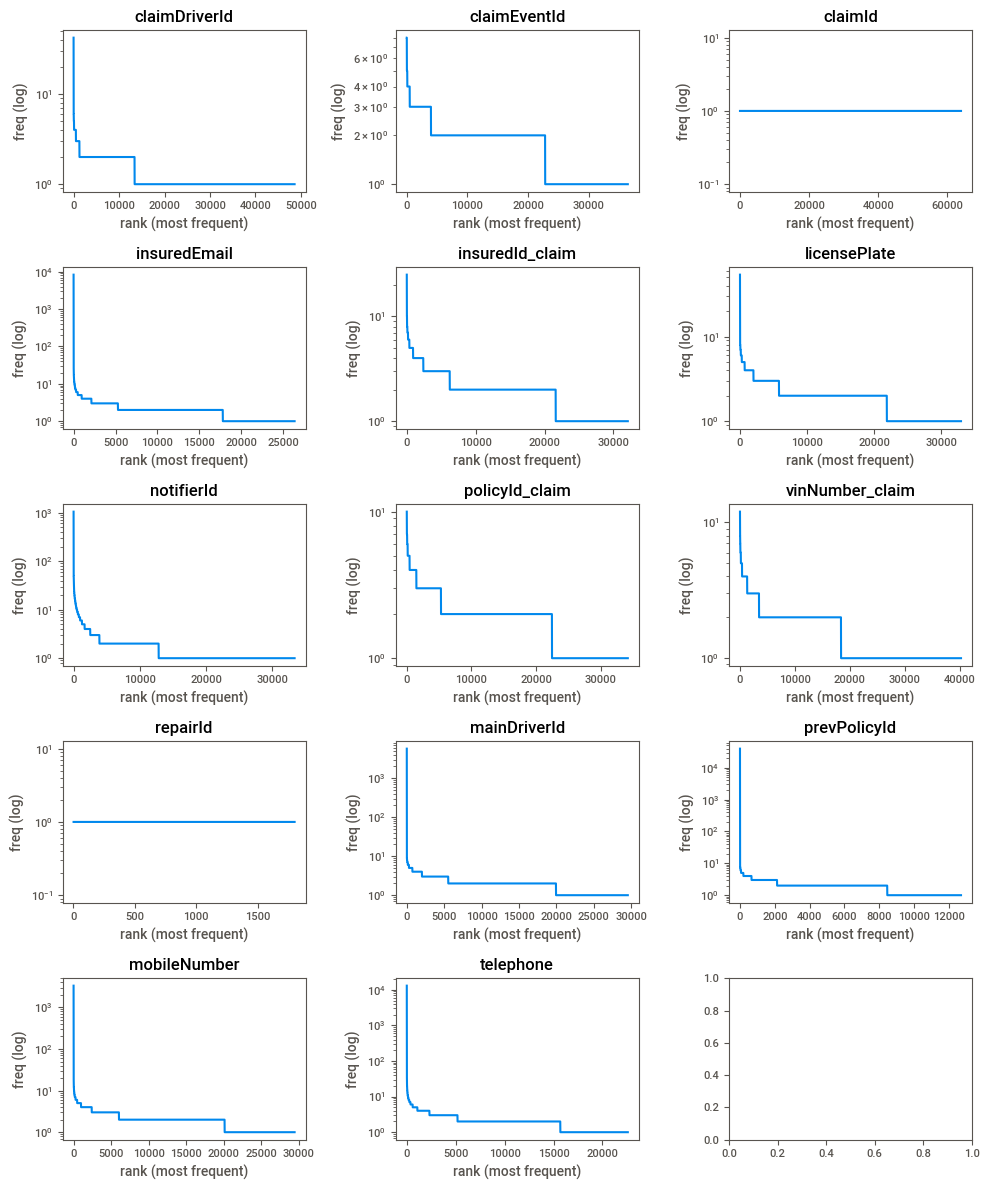

,col,top_val,n,%
0,claimDriverId,1120610.0,42.0,0.065682
1,claimEventId,1035856.0,8.0,0.012527
2,claimId,1103933.0,1.0,0.001564
3,insuredEmail,1286324.0,8345.0,13.050482
4,insuredId_claim,1238554.0,25.0,0.039097
5,licensePlate,1257163.0,54.0,0.084449
6,notifierId,1120610.0,1052.0,1.645190
7,policyId_claim,1277463.0,10.0,0.015639
8,vinNumber_claim,1364289.0,12.0,0.018766
9,repairId,1355891.0,1.0,0.055494


In [35]:
import matplotlib.pyplot as plt
import duckdb
import pandas as pd
from utils import get_frequency_table

top_vals = []
fig, axes = plt.subplots(5, 3, figsize=(10, 12))
for ax, col in zip(axes.flat, id_cols):

    vc_full = get_frequency_table(df[col].dropna()).iloc[:-1]

    top_val = vc_full.index[0]

    top_vals += [(col, top_val, vc_full.iloc[0]["n"], vc_full.iloc[0]["%"])]

    ax.plot(range(1, len(vc_full) + 1), vc_full["n"])
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("rank (most frequent)")
    ax.set_ylabel("freq (log)")

plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        top_vals,
        columns=["col", "top_val", "n", "%"]
    )
)

Frequency analysis points out that most id-like fields presents repeatable values in different levels (except `claimId` and `repairId`).   
However, that alone is not sufficient evidence to confirm these top values are placeholders.   
Given that, bellow is proposed a placeholder diagnosis for id-like columns.  
A frequent value is only treated as a placeholder **when two pieces of evidence combine**:
1. Presence in several columns (`n_cols`): codes are comparable across columns, so the same value in columns with different roles is suspicious.
2. Link to many distinct entities (`max_entities`): a value linked to `MIN_ENTITIES` or more entities (insureds, vehicles, policies...) does not identify a single person or thing.  

Verdict:
- placeholder: in 2+ columns and linked to many entities
- suspect:     in a single column, but linked to many entities (e.g. prevPolicyId)
- legit:       neither piece of evidence

In [ ]:
MIN_ENTITIES = 20

entity_cols = ['insuredId_claim', 'vinNumber_claim', 'policyId_claim',
               'claimDriverId', 'mainDriverId', 'notifierId']

# Which target columns each value appears in (long format, one row per non-null cell)
long = pd.concat([df[c].dropna().rename('value').to_frame().assign(col=c) for c in id_cols])
cols_by_value = long.groupby('value')['col'].agg(lambda s: sorted(set(s)))

rows = []
for col in id_cols:
    non_null = df[col].dropna()
    if non_null.is_unique:  # no repetition possible
        continue
    link_cols = [c for c in entity_cols if c != col]

    top = non_null.value_counts().head(1)
    val, n = top.index[0], top.iloc[0]

    sub = df.loc[df[col] == val]
    max_entities = max(sub[lc].nunique() for lc in link_cols)  # nunique ignores nulls
    found_in = cols_by_value[val]
    n_cols = len(found_in)

    if n_cols >= 2 and max_entities >= MIN_ENTITIES:
        verdict = 'placeholder'
    elif max_entities >= MIN_ENTITIES:
        verdict = 'suspect'
    else:
        verdict = 'legit'

    rows.append({
        'col': col, 'value': val, 'n_rows': n,
        'pct_non_null': round(n / len(non_null) * 100, 2),
        'n_cols': n_cols, 'found_in': ', '.join(found_in),
        'max_entities': max_entities, 'verdict': verdict,
    })

scan = pd.DataFrame(rows)
scan['verdict'] = pd.Categorical(scan['verdict'],
                                 categories=['placeholder', 'suspect', 'legit'],
                                 ordered=True)
scan = scan.sort_values(['verdict', 'n_rows'], ascending=[True, False]).reset_index(drop=True)
display(scan)

,col,value,n_rows,pct_non_null,n_cols,found_in,max_entities,verdict
0,prevPolicyId,1340592.0,39715,62.11,4,"licensePlate, mobileNumber, prevPolicyId, tele...",30522,placeholder
1,telephone,1120610.0,13078,20.45,7,"claimDriverId, insuredEmail, licensePlate, mai...",10582,placeholder
2,mainDriverId,1120610.0,5692,8.90,7,"claimDriverId, insuredEmail, licensePlate, mai...",4771,placeholder
3,mobileNumber,1120610.0,3336,5.22,7,"claimDriverId, insuredEmail, licensePlate, mai...",2833,placeholder
4,notifierId,1120610.0,1052,1.65,7,"claimDriverId, insuredEmail, licensePlate, mai...",1033,placeholder
5,claimDriverId,1120610.0,42,0.07,7,"claimDriverId, insuredEmail, licensePlate, mai...",36,placeholder
6,insuredId_claim,1238554.0,25,0.04,2,"insuredId_claim, notifierId",24,placeholder
7,insuredEmail,1286324.0,8345,13.05,1,insuredEmail,7051,suspect
8,licensePlate,1257163.0,54,0.08,1,licensePlate,44,suspect
9,vinNumber_claim,1364289.0,12,0.02,1,vinNumber_claim,9,legit


Following this criteria, most id-like variables present either placeholder values, or suspects.  
We'll assume from now on that values either classified as placeholder or suspect will be treated as placeholders.

### Checking consistency for `claimEventId`

The purpose of this analysis is to confirm whether `claimEventId` is a reliable key to group same-event claims (expected only 97% of multi-claims events)

In [ ]:
query = f"""
    WITH groups AS (
        SELECT vinNumber_claim, dateOcurr,
            count(DISTINCT claimEventId) AS nEventIds,
            count(*)                     AS nRows
        FROM '{parquet_path}'
        GROUP BY 1, 2
        HAVING count(*) > 1
    )
    SELECT
        nEventIds,
        count(*)                                   AS nGroups,
        count(*) / sum(count(*)) OVER ()           AS pctGroups,
        sum(nRows)                                 AS nClaimRows
    FROM groups
    GROUP BY 1
    ORDER BY 1
"""

display(duckdb.query(query).to_df().head(10))

,nEventIds,nGroups,pctGroups,nClaimRows
0,0,7,0.000373,15.0
1,1,18216,0.971520,38284.0
2,2,521,0.027787,1306.0
3,3,6,0.000320,21.0


Evidence confirms that `claimEventId` is not alone a reliable claim grouping key:
- Among the **18,750 (`vinNumber_claim`, `dateOcurr`) groups** with more than one row, the vast majority (**97.2%**, 18,216 groups) map to a single `claimEventId`.
- **2.8%** of groups (521) carry two distinct `claimEventId` values on the same vehicle and day, so the ID does not reliably identify the event in those cases.
- **0.04%** of groups (7) have only null `claimEventId` values, and 0.03% (6) have three distinct IDs.

Since we can't fully rely on `claimEventId` as a grouping of same-event claims, a possible alternative would be to group claims that are closely related in time.  
To do that we must first find what is the typical amplitude of hours between the first and the last same-day claims

In [38]:
# The query considers only the events we are mostly sure are correct
query = f"""
WITH clean_events AS (
    SELECT
      vinNumber_claim,
      dateOcurr,
      max(claimEventId) AS claimEventId
    FROM '{parquet_path}'
    GROUP BY 1,2
    HAVING COUNT(*) > 1
       AND count(DISTINCT claimEventId) = 1
)
SELECT
    b.claimEventId,
    b.vinNumber_claim,
    b.dateOcurr,
    min(date_trunc('minute', b.hourOfEvent)) AS min_hourOfEvent,
    max(date_trunc('minute', b.hourOfEvent)) AS max_hourOfEvent,
FROM '{parquet_path}' b
JOIN clean_events a
  ON a.vinNumber_claim = b.vinNumber_claim
 AND a.dateOcurr = b.dateOcurr
 AND a.claimEventId = b.claimEventId
GROUP BY 1,2,3
HAVING
  count(DISTINCT date_trunc('minute', b.hourOfEvent)) > 1
"""

df_events = duckdb.query(query).to_df()

display(df_events.head(10))


,claimEventId,vinNumber_claim,dateOcurr,min_hourOfEvent,max_hourOfEvent
0,1134938.0,1046958,2019-03-27,1970-01-01 18:00:00,1970-01-01 18:30:00
1,1035559.0,1293759,2019-03-25,1970-01-01 18:20:00,1970-01-01 18:35:00
2,1021805.0,1249047,2019-03-27,1970-01-01 13:04:00,1970-01-01 13:10:00
3,1050228.0,1241389,2019-03-25,1970-01-01 10:00:00,1970-01-01 15:15:00
4,1034918.0,1195380,2019-03-27,1970-01-01 14:00:00,1970-01-01 14:30:00
5,1037506.0,1038795,2019-03-22,1970-01-01 17:00:00,1970-01-01 17:10:00
6,1361145.0,1219583,2019-03-27,1970-01-01 07:00:00,1970-01-01 08:30:00
7,1052054.0,1290252,2019-03-26,1970-01-01 10:30:00,1970-01-01 10:42:00
8,1335906.0,1088624,2019-03-26,1970-01-01 18:23:00,1970-01-01 18:30:00
9,1119053.0,1299302,2019-03-20,1970-01-01 22:00:00,1970-01-01 22:30:00


Descriptive Statistics of hourOfEvent Amplitude (in hours):


,hour_amplitude
count,1993.000000
mean,1.265053
std,3.062491
min,0.016667
25%,0.166667
50%,0.333333
75%,0.833333
max,23.500000


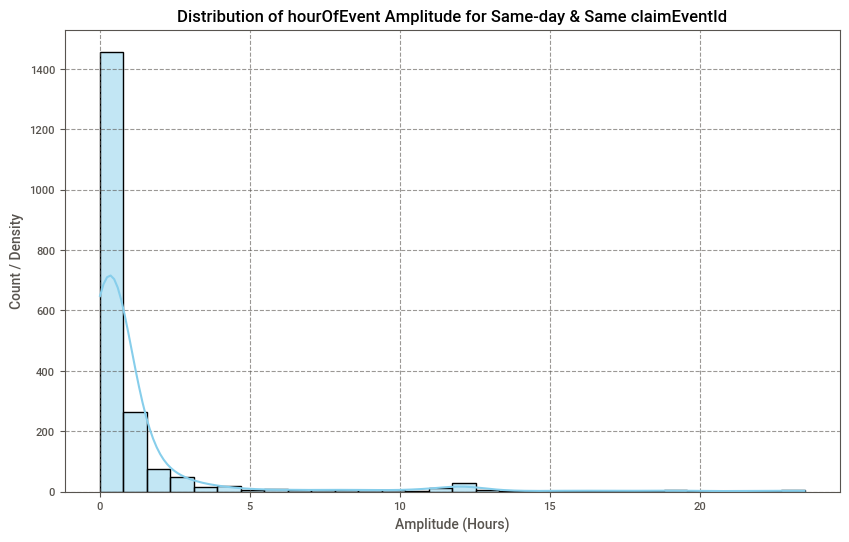

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the time amplitude directly from the min and max hourOfEvent columns
min_dt = pd.to_datetime(df_events['min_hourOfEvent'])
max_dt = pd.to_datetime(df_events['max_hourOfEvent'])

amplitude_df = df_events[['claimEventId', 'dateOcurr']].copy()
amplitude_df['hour_amplitude'] = (max_dt - min_dt).dt.total_seconds() / 3600.0

# Present descriptive statistics
print("Descriptive Statistics of hourOfEvent Amplitude (in hours):")
display(amplitude_df['hour_amplitude'].describe())

# Plot histogram with KDE
plt.figure(figsize=(10, 6))
sns.histplot(amplitude_df['hour_amplitude'], kde=True, bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of hourOfEvent Amplitude for Same-day & Same claimEventId')
plt.xlabel('Amplitude (Hours)')
plt.ylabel('Count / Density')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Evidence shows that around 75% percent of same-day event claims are made within an interval of ≈50min between the first and the last claim.      
While `claimEventId` remains the main grouping key, this may be helpful to disambiguate claims with same `vinNumber_claim` and `dateOcurr`, but different `claimEventIds`.   
Therefore, we could assume that distinct claims belong to the same event if:   
1. They share the same `claimEventId`; or
2. They share the same `vinNumber_claim` and `dateOcurr`, and also, the time between them are below a threshold (here assumed 50 min)   

Otherwise, there is no sufficient evidence to explicit determine they are somehow related

### Category spelling variants

Some categorical variables present variants of what seems to be the same category.  
This section explores whether these variants are just uninted misspelling errors, or they present potential signal the model could levarage to make predictions 

In [44]:
import re

# Variants follow the pattern "<category> (v2)", "<category> (v3)"...
# No normalization is applied here: this cell only lists them
variant_re = re.compile(r"\s*\(v(\d+)\)\s*$", re.IGNORECASE)

text_cols = df.select_dtypes(include=["object", "string"]).columns

rows = []
for col in text_cols:
    s = df[col].dropna()
    base = s.str.replace(variant_re, "", regex=True)
    version = s.str.extract(variant_re)[0].fillna("1").astype(int)

    tmp = pd.DataFrame({"category": base, "variant": s, "version": version})
    # keeps only categories that show up under more than one spelling
    tmp = tmp[tmp.groupby("category")["variant"].transform("nunique") > 1]
    if tmp.empty:
        continue

    counts = (tmp.groupby(["category", "variant", "version"]).size()
                 .rename("n").reset_index())
    counts.insert(0, "col", col)
    counts["pct_of_col"] = (counts["n"] / len(s) * 100).round(2)
    rows.append(counts)

variants = (pd.concat(rows)
              .sort_values(["col", "category", "version"])
              .reset_index(drop=True))

display(variants)
print(f"{variants['col'].nunique()} columns with spelling variants | "
      f"{variants['category'].nunique()} categories with more than one spelling")

,col,category,variant,version,n,pct_of_col
0,backupCar,No,No,1,60386,94.44
1,backupCar,No,No (v2),2,2384,3.73
2,claimCoverage,Collision,Collision,1,34261,53.74
3,claimCoverage,Collision,Collision (v2),2,21635,33.93
4,claimCoverage,Collision,Collision (v3),3,2101,3.30
5,claimCoverage,Non-collision,Non-collision,1,729,1.14
6,claimCoverage,Non-collision,Non-collision (v2),2,401,0.63
7,claimCoverage,Non-collision,Non-collision (v3),3,30,0.05
8,claimCoverage,Non-collision,Non-collision (v4),4,8,0.01
9,claimDriver,Main policy driver,Main policy driver,1,4168,7.35


10 columns with spelling variants | 19 categories with more than one spelling


Share of rows with a variant spelling, by year of loss (`dateOcurr`)

In [45]:
# Share of rows carrying a non-original spelling (version > 1), by year of loss
year = pd.to_datetime(df["dateOcurr"]).dt.year.astype("Int64").rename("year")

share = {}
for col in variants["col"].unique():
    s = df[col]
    is_variant = s.str.extract(variant_re)[0].notna().where(s.notna())
    share[col] = is_variant.groupby(year).mean()

share_by_year = pd.DataFrame(share)
share_by_year.insert(0, "n_rows", year.value_counts().sort_index())

display(
    share_by_year.style
    .format({c: "{:.0%}" for c in share_by_year.columns[1:]}, na_rep="-")
    .background_gradient(cmap="Blues", subset=share_by_year.columns[1:], vmin=0, vmax=1)
)

,n_rows,backupCar,claimCoverage,claimDriver,notifier,personalInjury,policeRepOnline,policeReport,under25Cov,useOfVehicle,vehicleCategory
year,,,,,,,,,,,
2008,1,0%,100%,0%,0%,0%,0%,0%,0%,100%,0%
2016,4,0%,0%,-,-,0%,0%,0%,0%,100%,0%
2017,84,6%,38%,0%,0%,6%,6%,4%,0%,84%,0%
2018,4535,0%,94%,0%,0%,0%,0%,0%,0%,80%,0%
2019,13251,0%,94%,0%,0%,0%,0%,0%,0%,71%,0%
2020,11693,20%,64%,4%,0%,20%,18%,12%,4%,51%,0%
2021,9550,0%,0%,0%,0%,0%,0%,0%,0%,65%,0%
2022,11777,0%,0%,0%,0%,0%,0%,0%,0%,36%,0%
2023,11922,0%,0%,0%,0%,0%,0%,0%,0%,4%,0%


The same category appears under several spellings, marked with a `(vN)` suffix (e.g. `Collision`, `Collision (v2)`, `Collision (v3)`).  
No normalization is applied at this stage, since the spelling may carry information for the model.   
Notes:  
- 10 text columns have variants, covering 19 categories and about 55% of the rows (at least one variant).
- Variants are not random typos: their share changes a lot by year of loss. For example, `claimCoverage` variants account for about 94% of 2018-2019 rows and none from 2021 on, while `useOfVehicle` moves from `(v2)` towards the original spelling by 2023.
- Flag-like columns (`backupCar`, `personalInjury`, `policeReport`, `policeRepOnline`, `under25Cov`) carry `(v2)` almost only in 2017 and 2020 (about 20% of 2020 rows).
- The variant may therefore work as a proxy for period or source-system version.   

The decision on how to treat it is left open for now, and will depend on how well the model will perform according to the signals of these variables.
